In [3]:
import numpy as np
import matplotlib.pyplot as plt


def v_circ(mu, r):
    return np.sqrt(mu / r)

def v_ell(mu, r, a):
    # vis-viva
    return np.sqrt(mu * (2.0/r - 1.0/a))

def period_ell(mu, a):
    return 2.0*np.pi*np.sqrt(a**3/mu)

def hohmann(mu, r1, r2):
    """
    Hohmann tra orbite circolari coplanari di raggio r1 -> r2.
    Output: dv1, dv2, dv_tot, tof (mezzo periodo ellisse di trasferimento)
    """
    r1 = float(r1); r2 = float(r2)
    a_t = 0.5*(r1 + r2)

    v1 = v_circ(mu, r1)
    v2 = v_circ(mu, r2)

    vt_r1 = v_ell(mu, r1, a_t)  # velocità su ellisse al r1
    vt_r2 = v_ell(mu, r2, a_t)  # velocità su ellisse al r2

    dv1 = abs(vt_r1 - v1)
    dv2 = abs(v2 - vt_r2)

    dv_tot = dv1 + dv2
    tof = 0.5*period_ell(mu, a_t)

    return {"a_t": a_t, "dv1": dv1, "dv2": dv2, "dv_tot": dv_tot, "tof": tof}

def bielliptic(mu, r1, r2, rb):
    """
    Bi-ellittico tra orbite circolari coplanari r1 -> r2 via rb (apoapsi comune).
    Implementazione standard con rb >= max(r1,r2).
    Output: dv1,dv2,dv3,dv_tot,tof.
    """
    r1 = float(r1); r2 = float(r2); rb = float(rb)
    if rb < max(r1, r2):
        raise ValueError("Richiesto rb >= max(r1, r2) per il bi-ellittico standard.")

    v1 = v_circ(mu, r1)
    v2 = v_circ(mu, r2)

    # Ellisse 1: pericentro=min(r1,rb) ma qui per costruzione pericentro=r1, apocentro=rb
    a1 = 0.5*(r1 + rb)
    v1e_r1 = v_ell(mu, r1, a1)
    v1e_rb = v_ell(mu, rb, a1)

    # Ellisse 2: pericentro=r2, apocentro=rb
    a2 = 0.5*(r2 + rb)
    v2e_r2 = v_ell(mu, r2, a2)
    v2e_rb = v_ell(mu, rb, a2)

    dv1 = abs(v1e_r1 - v1)       # burn a r1
    dv2 = abs(v2e_rb - v1e_rb)   # burn a rb
    dv3 = abs(v2 - v2e_r2)       # burn a r2

    dv_tot = dv1 + dv2 + dv3
    tof = 0.5*period_ell(mu, a1) + 0.5*period_ell(mu, a2)

    return {"a1": a1, "a2": a2, "dv1": dv1, "dv2": dv2, "dv3": dv3, "dv_tot": dv_tot, "tof": tof}


In [4]:
# Costanti
AU = 149_597_870.7  # km  (definizione moderna)  (fonte: AU)
mu_sun = 1.32712440041279419e11  # km^3/s^2 (convertito da m^3/s^2 JPL: *1e-9)

r1 = 1.0 * AU
r2 = 1.52368055 * AU  # Marte (semi-major axis)

# Hohmann Terra->Marte
H = hohmann(mu_sun, r1, r2)
print("=== Hohmann eliocentrico Terra -> Marte ===")
print(f"Δv1 = {H['dv1']:.6f} km/s")
print(f"Δv2 = {H['dv2']:.6f} km/s")
print(f"Δv_tot = {H['dv_tot']:.6f} km/s")
print(f"ToF = {H['tof']/86400:.3f} giorni")


=== Hohmann eliocentrico Terra -> Marte ===
Δv1 = 2.944696 km/s
Δv2 = 2.648900 km/s
Δv_tot = 5.593596 km/s
ToF = 258.866 giorni


Hohmann Δv_tot: 5.593596331213266 km/s
Min bi-elliptic Δv_tot nello sweep: 5.593596331213266 km/s
rb_best [AU]: 1.52368055
ToF_best [giorni]: 602.3522159117935


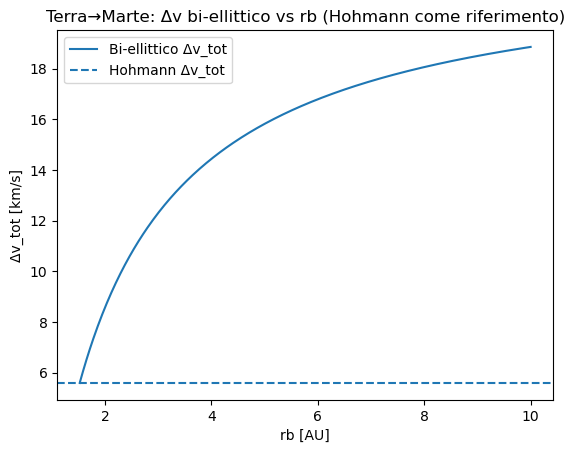

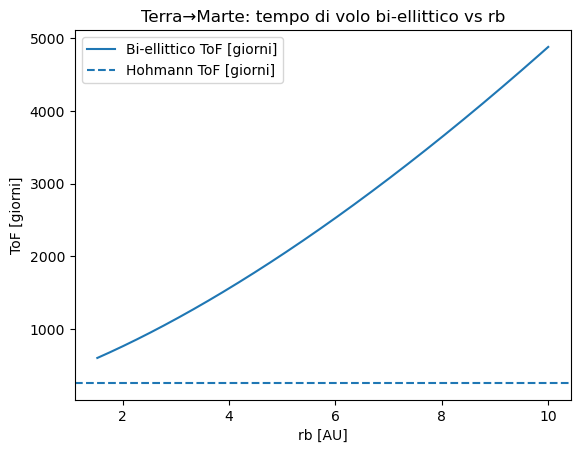

In [13]:
rb_grid = np.linspace(r2, 10*AU, 400)  # sweep da r2 a 10 AU
dv_b = []
tof_b = []

for rb in rb_grid:
    B = bielliptic(mu_sun, r1, r2, rb)
    dv_b.append(B["dv_tot"])
    tof_b.append(B["tof"])

dv_b = np.array(dv_b)
tof_b = np.array(tof_b)

print("Hohmann Δv_tot:", H["dv_tot"], "km/s")
print("Min bi-elliptic Δv_tot nello sweep:", dv_b.min(), "km/s")
print("rb_best [AU]:", (rb_grid[dv_b.argmin()]/AU))
print("ToF_best [giorni]:", tof_b[dv_b.argmin()]/86400)

plt.figure()
plt.plot(rb_grid/AU, dv_b, label="Bi-ellittico Δv_tot")
plt.axhline(H["dv_tot"], linestyle="--", label="Hohmann Δv_tot")
plt.xlabel("rb [AU]")
plt.ylabel("Δv_tot [km/s]")
plt.legend()
plt.title("Terra→Marte: Δv bi-ellittico vs rb (Hohmann come riferimento)")
plt.show()

plt.figure()
plt.plot(rb_grid/AU, tof_b/86400, label="Bi-ellittico ToF [giorni]")
plt.axhline(H["tof"]/86400, linestyle="--", label="Hohmann ToF [giorni]")
plt.xlabel("rb [AU]")
plt.ylabel("ToF [giorni]")
plt.legend()
plt.title("Terra→Marte: tempo di volo bi-ellittico vs rb")
plt.show()


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

base_dir = Path.cwd()          # directory del notebook
out_gif = base_dir / "hohmann_earth_to_mars.gif"

out_dir = Path.cwd() / "output"
out_dir.mkdir(exist_ok=True)


# -------------------------
# Parametri (unità: AU)
# -------------------------
rE = 1.0
rM = 1.523679
TE = 1.0
TM = 1.8808

# Mean motions (rad/anno)
nE = 2*np.pi/TE
nM = 2*np.pi/TM

# Orbita di trasferimento Hohmann
r1, r2 = rE, rM
a_t = 0.5*(r1 + r2)
e_t = (r2 - r1)/(r2 + r1)
p_t = a_t*(1 - e_t**2)

# Mean motion trasferimento (scalato su Earth-year: n(1AU)=2π/anno)
nT = 2*np.pi * (a_t**(-1.5))
ToF = np.pi/nT  # anni

# Fase iniziale di Marte per arrivo a nu=pi dopo ToF
theta_E0 = 0.0
theta_M0 = (np.pi - nM*ToF) % (2*np.pi)

def kepler_E_from_M(M, e, tol=1e-12, maxit=50):
    E = M
    for _ in range(maxit):
        f  = E - e*np.sin(E) - M
        fp = 1 - e*np.cos(E)
        dE = -f/fp
        E  = E + dE
        if np.max(np.abs(dE)) < tol:
            break
    return E

def sc_state(t):
    # t in anni, da 0 a ToF
    M = nT*t
    E = kepler_E_from_M(M, e_t)
    nu = 2*np.arctan2(np.sqrt(1+e_t)*np.sin(E/2), np.sqrt(1-e_t)*np.cos(E/2))
    r  = p_t/(1 + e_t*np.cos(nu))
    return r*np.cos(nu), r*np.sin(nu)

def circ_state(r, theta):
    return r*np.cos(theta), r*np.sin(theta)

# -------------------------
# Rendering GIF manuale
# -------------------------
fps = 30
duration_s = 12
frames = fps*duration_s
t_grid = np.linspace(0, ToF, frames)

# Precompute per traccia sonda
sc_xy = np.array([sc_state(t) for t in t_grid])

theta = np.linspace(0, 2*np.pi, 2000)
earth_orbit = np.c_[rE*np.cos(theta), rE*np.sin(theta)]
mars_orbit  = np.c_[rM*np.cos(theta), rM*np.sin(theta)]

nu = np.linspace(0, 2*np.pi, 2000)
r  = p_t/(1 + e_t*np.cos(nu))
transfer_orbit = np.c_[r*np.cos(nu), r*np.sin(nu)]

lim = 1.75*rM

images = []
fig, ax = plt.subplots(figsize=(7,7), dpi=120)
ax.set_aspect("equal", "box")
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.set_title("Trasferimento Hohmann Terra → Marte (eliocentrico)")

# Statiche
ax.plot(earth_orbit[:,0], earth_orbit[:,1], lw=1)
ax.plot(mars_orbit[:,0],  mars_orbit[:,1],  lw=1)
ax.plot(transfer_orbit[:,0], transfer_orbit[:,1], lw=1, ls="--")

# Sole
ax.plot(0, 0, marker="o", markersize=10)

# Artisti aggiornabili
earth_dot, = ax.plot([], [], marker="o", markersize=7)
mars_dot,  = ax.plot([], [], marker="o", markersize=7)
sc_dot,    = ax.plot([], [], marker="o", markersize=5)
sc_path,   = ax.plot([], [], lw=1)

time_text = ax.text(0.02, 0.98, "", transform=ax.transAxes, va="top")

for i, t in enumerate(t_grid):
    # pianeti
    thetaE = theta_E0 + nE*t
    thetaM = theta_M0 + nM*t
    xE, yE = circ_state(rE, thetaE)
    xM, yM = circ_state(rM, thetaM)

    earth_dot.set_data([xE], [yE])
    mars_dot.set_data([xM], [yM])

    # sonda
    xS, yS = sc_xy[i]
    sc_dot.set_data([xS], [yS])
    sc_path.set_data(sc_xy[:i+1,0], sc_xy[:i+1,1])

    t_days = 365.25*t
    time_text.set_text(f"t = {t_days:.1f} giorni   (ToF ≈ {365.25*ToF:.1f} giorni)")

    # render frame -> PIL image
    fig.canvas.draw()
    w, h = fig.canvas.get_width_height()
    buf = np.frombuffer(fig.canvas.tostring_argb(), dtype=np.uint8).reshape(h, w, 4)
    # ARGB -> RGBA
    buf = buf[:, :, [1,2,3,0]]
    images.append(Image.fromarray(buf, mode="RGBA"))

plt.close(fig)

out_gif = out_dir / "hohmann_earth_to_mars.gif"
images[0].save(
    out_gif,
    save_all=True,
    append_images=images[1:],
    duration=int(1000/fps),
    loop=0,
    disposal=2
)

print(f"Salvato: {out_gif}")


Salvato: /Users/marcobellomo/Documents/Val d'Aosta/output/hohmann_earth_to_mars.gif


In [7]:
# ============================================================
# Earth -> Mars con effemeridi reali (JPL DE440s via Skyfield)
# + Lambert (2-body Sole) + propagazione kepleriana + GIF
#
# Output: gif nella stessa cartella del notebook
#
# Requisiti:
#   pip install skyfield numpy matplotlib pillow
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# -------------------------
# 0) Effemeridi reali (DE440s)
# -------------------------
%pip install skyfield
from skyfield.api import load

ts = load.timescale()

# Skyfield scarica automaticamente de440s se non presente
# (puoi anche mettere il file in locale e dare il path)
eph = load('de440s.bsp')  # :contentReference[oaicite:1]{index=1}

sun   = eph['sun']
earth = eph['earth barycenter']
mars  = eph['mars barycenter']


# -------------------------
# 1) Scelte di missione (modificabili)
# -------------------------
t0_utc   = "2026-01-26 00:00:00"   # data partenza (UTC)
tof_days = 259.0                  # tempo di volo (giorni), ~ Hohmann classico (ma qui con orbite reali)

t0 = ts.utc(*map(int, t0_utc.replace("-", " ").replace(":", " ").split()))
t1 = ts.tt_jd(t0.tt + tof_days)   # arrivo dopo tof_days

# -------------------------
# 2) Vettori r(t) eliocentrici reali (AU) a t0 e t1
# -------------------------
# Posizioni eliocentriche: planet - sun
r1_au = (earth.at(t0) - sun.at(t0)).position.au
r2_au = (mars.at(t1)  - sun.at(t1)).position.au

r1 = np.array(r1_au, dtype=float)
r2 = np.array(r2_au, dtype=float)

# -------------------------
# 3) Lambert solver (universale) — short-way, 2-body
#    Ritorna v1, v2 tali che r1 -> r2 in dt
# -------------------------
AU_km = 149_597_870.7  # km (per scalare mu) :contentReference[oaicite:2]{index=2}
mu_sun_km = 1.32712440041279419e11  # km^3/s^2 (valore standard JPL/IAU)

# Convertiamo in km per usare mu in km^3/s^2
r1_km = r1 * AU_km
r2_km = r2 * AU_km
dt = tof_days * 86400.0

def stumpff_C(z):
    if z > 0:
        sz = np.sqrt(z)
        return (1 - np.cos(sz)) / z
    elif z < 0:
        sz = np.sqrt(-z)
        return (np.cosh(sz) - 1) / (-z)
    else:
        return 0.5

def stumpff_S(z):
    if z > 0:
        sz = np.sqrt(z)
        return (sz - np.sin(sz)) / (sz**3)
    elif z < 0:
        sz = np.sqrt(-z)
        return (np.sinh(sz) - sz) / (sz**3)
    else:
        return 1/6

def lambert_universal(r1, r2, dt, mu, maxit=100, tol=1e-8, short=True):
    r1n = np.linalg.norm(r1)
    r2n = np.linalg.norm(r2)
    cos_dtheta = np.dot(r1, r2)/(r1n*r2n)
    cos_dtheta = np.clip(cos_dtheta, -1.0, 1.0)
    dtheta = np.arccos(cos_dtheta)

    # scelta short/long way
    if not short:
        dtheta = 2*np.pi - dtheta

    A = np.sin(dtheta) * np.sqrt(r1n*r2n/(1 - np.cos(dtheta)))
    if abs(A) < 1e-12:
        raise RuntimeError("Geometria Lambert degenerata (A≈0). Cambia date/ToF.")

    # solve per z con Newton su F(z)=0
    z = 0.0
    for _ in range(maxit):
        C = stumpff_C(z)
        S = stumpff_S(z)
        y = r1n + r2n + A*(z*S - 1)/np.sqrt(C)

        # y deve essere positivo
        if y < 0:
            z += 0.1
            continue

        x = np.sqrt(y/C)
        dt_z = (x**3*S + A*np.sqrt(y))/np.sqrt(mu)

        F = dt_z - dt
        if abs(F) < tol:
            break

        # derivata numerica robusta
        dz = 1e-3
        Cp = stumpff_C(z+dz); Sp = stumpff_S(z+dz)
        yp = r1n + r2n + A*((z+dz)*Sp - 1)/np.sqrt(Cp)
        if yp <= 0:
            z += 0.1
            continue
        xp = np.sqrt(yp/Cp)
        dt_p = (xp**3*Sp + A*np.sqrt(yp))/np.sqrt(mu)
        dFdz = (dt_p - dt_z)/dz

        z = z - F/dFdz

    C = stumpff_C(z)
    S = stumpff_S(z)
    y = r1n + r2n + A*(z*S - 1)/np.sqrt(C)
    f = 1 - y/r1n
    g = A*np.sqrt(y/mu)
    gdot = 1 - y/r2n

    v1 = (r2 - f*r1)/g
    v2 = (gdot*r2 - r1)/g
    return v1, v2, dtheta

v1_km_s, v2_km_s, dtheta = lambert_universal(r1_km, r2_km, dt, mu_sun_km, short=True)

print("=== Lambert (effemeridi reali) ===")
print(f"Data partenza (UTC): {t0_utc}")
print(f"ToF: {tof_days:.1f} giorni")
print(f"Trasferimento: Δθ ≈ {np.degrees(dtheta):.1f} deg (short-way)")
print(f"|v1| = {np.linalg.norm(v1_km_s):.3f} km/s  |v2| = {np.linalg.norm(v2_km_s):.3f} km/s")

# -------------------------
# 4) Propagazione kepleriana eliocentrica della sonda (2-body)
#    con metodo universale (f,g) da stato iniziale (r1,v1)
# -------------------------
def propagate_universal(r0, v0, dt, mu, tol=1e-10, maxit=50):
    r0n = np.linalg.norm(r0)
    v0n = np.linalg.norm(v0)
    vr0 = np.dot(r0, v0)/r0n
    alpha = 2/r0n - v0n**2/mu

    # initial guess for chi
    if abs(alpha) > 1e-12:
        chi = np.sqrt(mu)*abs(alpha)*dt
    else:
        chi = np.sqrt(mu)*dt/r0n

    for _ in range(maxit):
        z = alpha*chi**2
        C = stumpff_C(z)
        S = stumpff_S(z)

        F = (r0n*vr0/np.sqrt(mu))*chi**2*C + (1 - alpha*r0n)*chi**3*S + r0n*chi - np.sqrt(mu)*dt
        dF = (r0n*vr0/np.sqrt(mu))*chi*(1 - z*S) + (1 - alpha*r0n)*chi**2*C + r0n

        dchi = -F/dF
        chi += dchi
        if abs(dchi) < tol:
            break

    z = alpha*chi**2
    C = stumpff_C(z)
    S = stumpff_S(z)

    f = 1 - (chi**2/r0n)*C
    g = dt - (1/np.sqrt(mu))*chi**3*S

    r = f*r0 + g*v0
    rn = np.linalg.norm(r)

    fdot = (np.sqrt(mu)/(rn*r0n))*(alpha*chi**3*S - chi)
    gdot = 1 - (chi**2/rn)*C

    v = fdot*r0 + gdot*v0
    return r, v

# -------------------------
# 5) Video GIF (senza ffmpeg), con pianeti da effemeridi reali
# -------------------------
fps = 30
duration_s = 12
frames = fps*duration_s

t_grid_days = np.linspace(0, tof_days, frames)
t_grid_sec  = t_grid_days * 86400.0

# Pianeti (posizioni eliocentriche reali campionate)
earth_xy = np.zeros((frames, 2))
mars_xy  = np.zeros((frames, 2))
sc_xy    = np.zeros((frames, 2))

for i, dd in enumerate(t_grid_days):
    ti = ts.tt_jd(t0.tt + dd)
    rE_i = (earth.at(ti) - sun.at(ti)).position.au
    rM_i = (mars.at(ti)  - sun.at(ti)).position.au
    earth_xy[i] = rE_i[:2]
    mars_xy[i]  = rM_i[:2]

    r_sc_km, _ = propagate_universal(r1_km, v1_km_s, t_grid_sec[i], mu_sun_km)
    sc_xy[i] = (r_sc_km[:2] / AU_km)

# Tracce statiche: un anno di orbita reale attorno a t0 (per contesto)
N_orb = 800
span_days = 700  # finestra grafica
tt_orb = ts.tt_jd(t0.tt + np.linspace(-span_days/2, span_days/2, N_orb))
E_orb = (earth.at(tt_orb) - sun.at(tt_orb)).position.au
M_orb = (mars.at(tt_orb)  - sun.at(tt_orb)).position.au

# Rendering manuale
lim = 1.8*np.max(np.linalg.norm(M_orb[:2], axis=0))
images = []

fig, ax = plt.subplots(figsize=(7,7), dpi=120)
ax.set_aspect("equal", "box")
ax.set_xlim(-2.0, 2.0)  # AU (fisso per chiarezza)
ax.set_ylim(-2.0, 2.0)
ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.set_title("Terra → Marte con orbite reali (DE440s) + Lambert")

ax.plot(E_orb[0], E_orb[1], lw=1, label="Terra (effemeridi)")
ax.plot(M_orb[0], M_orb[1], lw=1, label="Marte (effemeridi)")
ax.plot(0, 0, marker="o", markersize=10, label="Sole")

earth_dot, = ax.plot([], [], marker="o", markersize=7, label="Terra")
mars_dot,  = ax.plot([], [], marker="o", markersize=7, label="Marte")
sc_dot,    = ax.plot([], [], marker="o", markersize=5, label="Sonda")
sc_path,   = ax.plot([], [], lw=1, alpha=0.9, label="Traiettoria (Lambert)")

txt = ax.text(0.02, 0.98, "", transform=ax.transAxes, va="top")
ax.legend(loc="lower left")

for i in range(frames):
    earth_dot.set_data([earth_xy[i,0]], [earth_xy[i,1]])
    mars_dot.set_data([mars_xy[i,0]],   [mars_xy[i,1]])
    sc_dot.set_data([sc_xy[i,0]],       [sc_xy[i,1]])
    sc_path.set_data(sc_xy[:i+1,0], sc_xy[:i+1,1])

    txt.set_text(f"t = {t_grid_days[i]:.1f} giorni  (ToF={tof_days:.1f} d)\n"
                 f"t0={t0_utc} UTC")

    fig.canvas.draw()
    w, h = fig.canvas.get_width_height()
    buf = np.frombuffer(fig.canvas.tostring_argb(), dtype=np.uint8).reshape(h, w, 4)
    buf = buf[:, :, [1,2,3,0]]  # ARGB -> RGBA
    images.append(Image.fromarray(buf, mode="RGBA"))

plt.close(fig)

out_gif = "earth_to_mars_real_ephemeris_lambert.gif"
images[0].save(out_gif, save_all=True, append_images=images[1:],
               duration=int(1000/fps), loop=0, disposal=2)
print(f"Salvato: {out_gif}")


Note: you may need to restart the kernel to use updated packages.
=== Lambert (effemeridi reali) ===
Data partenza (UTC): 2026-01-26 00:00:00
ToF: 259.0 giorni
Trasferimento: Δθ ≈ 34.9 deg (short-way)
|v1| = 30.658 km/s  |v2| = 16.334 km/s
Salvato: earth_to_mars_real_ephemeris_lambert.gif


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

out_dir = Path.cwd() / "output"
out_dir.mkdir(exist_ok=True)

# --- FUNZIONI CORRETTE (vis-viva, normalizzate a v_initial) ---

def dv_hohmann_norm(R):
    R = np.asarray(R, dtype=float)
    a = 0.5*(1.0 + R)
    vp = np.sqrt(2.0 - 1.0/a)              # v al perigeo (r1=1)
    va = np.sqrt(2.0/R - 1.0/a)            # v all'apogeo (r2=R)
    dv1 = np.abs(vp - 1.0)                 # v_c1 = 1 in unità normalizzate
    dv2 = np.abs(1.0/np.sqrt(R) - va)      # v_c2 = 1/sqrt(R)
    return dv1 + dv2

def dv_bielliptic_norm(R, Rstar):
    R = np.asarray(R, dtype=float)
    Rstar = float(Rstar)

    a1 = 0.5*(1.0 + Rstar)
    a2 = 0.5*(R + Rstar)

    vp1 = np.sqrt(2.0 - 1.0/a1)                 # perigeo ellisse 1 (r=1)
    va1 = np.sqrt(2.0/Rstar - 1.0/a1)           # apogeo ellisse 1 (r=R*)
    va2 = np.sqrt(2.0/Rstar - 1.0/a2)           # apogeo ellisse 2 (r=R*)
    vp2 = np.sqrt(2.0/R - 1.0/a2)               # perigeo ellisse 2 (r=R)

    dv1 = np.abs(vp1 - 1.0)
    dv2 = np.abs(va2 - va1)
    dv3 = np.abs(1.0/np.sqrt(R) - vp2)
    return dv1 + dv2 + dv3

# --- SCALA FISICA DELL’ARTICOLO ---
v_initial_kms = 7.905  # 1 ER/TU = 7.905 km/s

# --- DOMINIO (come figura) ---
R = np.linspace(1.0, 75.0, 3000)

# Curve
dvH = v_initial_kms * dv_hohmann_norm(R)

Rstars = [15.58, 40, 60, 100, 200]
Rstar_inf = 1e9  # approssima R* -> infinito

plt.figure(figsize=(9,6), dpi=150)

plt.plot(R, dvH, lw=2.8, label="Hohmann")

for Rs in Rstars:
    plt.plot(R, v_initial_kms * dv_bielliptic_norm(R, Rs),
             lw=1.2, label=rf"$R^*={Rs}$")

plt.plot(R, v_initial_kms * dv_bielliptic_norm(R, Rstar_inf),
         lw=1.5, label=r"$R^*=\infty$")

# Soglie classiche
plt.axvline(11.94, lw=1, linestyle="--")
plt.axvline(15.58, lw=1, linestyle="--")

plt.xlim(1, 75)
plt.ylim(3.3, 4.7)  # circa come nella figura che hai mostrato (puoi togliere se vuoi auto-scale)
plt.xlabel(r"$R$")
plt.ylabel("Change in Velocity (km/s)")
plt.title("Hohmann vs Bi-elliptic (scaled to $v_{initial}=7.905$ km/s)")
plt.grid(True, alpha=0.25)
plt.legend(ncols=2, fontsize=9)
plt.tight_layout()

fig_path = out_dir / "dv_vs_R_like_paper.png"
plt.savefig(fig_path)
plt.close()

print("Salvato:", fig_path)


Salvato: /Users/marcobellomo/Documents/Val d'Aosta/output/dv_vs_R_like_paper.png
